# Biblio

In [1]:
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [11]:
# Import de nos fonctions utils
sys.path.append(os.path.abspath("."))
import utils_credit

print("Pandas version :", pd.__version__)
print("Numpy version  :", np.__version__)

Pandas version : 3.0.6
Numpy version  : 2.4.6


# 1. Préparer Credit Card

## a. Examiner les données

- Types des colonnes
- Recherche de valeurs manquantes
- Détection et suppression des doublons
- Proportion de fraudes
- Gestion de Time et découpage stratifié (60% Train / 20% Val / 20% Test)

### Examen initial (types, valeurs manquantes, doublons)

In [8]:
# Chargement brut pour inspection
df_raw = pd.read_csv("../data/creditcard.csv")

print(f"Dimensions : {df_raw.shape[0]} lignes, {df_raw.shape[1]} colonnes")
print(f"Valeurs manquantes totales : {df_raw.isna().sum().sum()}")

# Comptage des doublons
n_doublons = df_raw.duplicated().sum()
print(f"Nombre de doublons stricts : {n_doublons}")

# Affichage des types de variables
print(df_raw.dtypes.value_counts())


Dimensions : 284807 lignes, 31 colonnes
Valeurs manquantes totales : 0
Nombre de doublons stricts : 1081
float64    30
int64       1
Name: count, dtype: int64


### Nettoyage des doublons et calcul du déséquilibre

In [4]:
# Nettoyage via utils (suppression des doublons)
df = utils.load_clean_data("../data/creditcard.csv")

# Proportion de fraudes
comptes = df["Class"].value_counts()
pct_fraude = (comptes[1] / len(df)) * 100

print(f"Transactions normales (0) : {comptes[0]}")
print(f"Fraudes (1)               : {comptes[1]}")
print(f"Proportion de fraudes     : {pct_fraude:.3f}%")

Transactions normales (0) : 283253
Fraudes (1)               : 473
Proportion de fraudes     : 0.167%


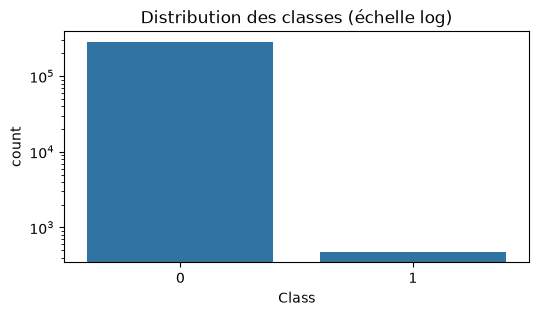

In [5]:
# Graphique simple du déséquilibre
plt.figure(figsize=(6, 3))
sns.countplot(x="Class", data=df)
plt.yscale("log")
plt.title("Distribution des classes (échelle log)")
plt.show()

### Découpage stratifié (60% Train / 20% Val / 20% Test)

In [6]:
# Découpage avec Time et Class écartés de X
X_train, X_val, X_test, y_train, y_val, y_test = utils.split_data(
    df, random_state=42
)

# Vérification des effectifs et du taux de fraude
for nom, y_part in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
  n_f = (y_part == 1).sum()
  taux = (n_f / len(y_part)) * 100
  print(
      f"{nom:<5} : {len(y_part)} transactions | {n_f} fraudes"
      f" ({taux:.3f}%)"
  )


Train : 170235 transactions | 284 fraudes (0.167%)
Val   : 56745 transactions | 94 fraudes (0.166%)
Test  : 56746 transactions | 95 fraudes (0.167%)


### Analyse de Time et limites du découpage aléatoire

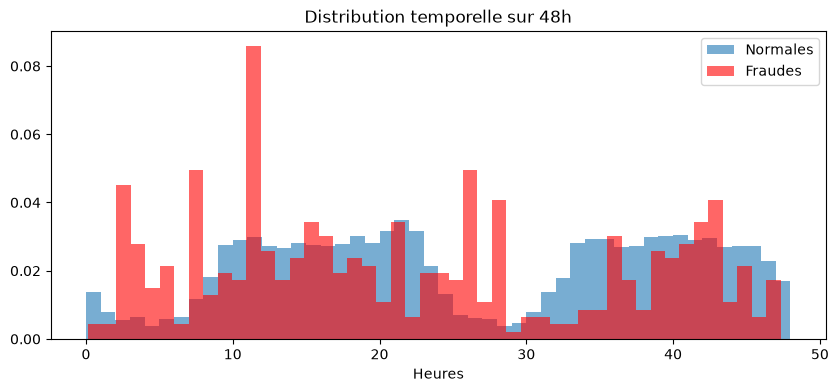

In [7]:
# Visualisation de la distribution de Time (en heures)
time_heures = df["Time"] / 3600

plt.figure(figsize=(10, 4))
plt.hist(
    time_heures[df["Class"] == 0],
    bins=48,
    alpha=0.6,
    label="Normales",
    density=True,
)
plt.hist(
    time_heures[df["Class"] == 1],
    bins=48,
    alpha=0.6,
    label="Fraudes",
    color="red",
    density=True,
)
plt.title("Distribution temporelle sur 48h")
plt.xlabel("Heures")
plt.legend()
plt.show()

#### Limites du découpage aléatoire par rapport à la variable Time :

1. **Fuite temporelle (Data leakage / interpolation) :**
   Un découpage aléatoire mélange les données du jour 1 et du jour 2. Le modèle risque donc d'apprendre sur des transactions du futur pour prédire des fraudes du passé, ce qui est impossible dans la réalité.

2. **Dérive de concept (Concept Drift) :**
   Les comportements légitimes suivent des cycles jour/nuit (creux la nuit, pics le jour), alors que les méthodes des fraudeurs s'adaptent et évoluent en permanence dans le temps.

3. **Inadéquation avec la production réelle :**
   En conditions réelles dans une banque, on s'entraîne toujours sur le passé ($t < T$) pour prédire sur le futur ($t \ge T$). Un découpage chronologique serait donc indispensable en pratique. Nous écartons `Time` des prédicteurs pour cette comparaison afin d'éviter qu'il n'apprenne des corrélations temporelles factices.


## b. Étude des échelles des variables et prétraitement

### Observer les échelles (Amount vs V1 à V28)

In [9]:
# 1. Statistiques de Amount
print("Statistiques de la variable Amount (Train)")
print(X_train["Amount"].describe())

# 2. Statistiques moyennes des variables V1 à V28
print("\nÉchelle des variables V1 à V28 (Train)")
v_cols = [col for col in X_train.columns if col.startswith("V")]
print("Moyenne générale de V1..V28     :", round(X_train[v_cols].mean().mean(), 4))
print("Écart-type moyen de V1..V28     :", round(X_train[v_cols].std().mean(), 4))
print("Valeur min de V1..V28 (extrême) :", round(X_train[v_cols].min().min(), 2))
print("Valeur max de V1..V28 (extrême) :", round(X_train[v_cols].max().max(), 2))


Statistiques de la variable Amount (Train)
count    170235.000000
mean         88.304887
std         243.916503
min           0.000000
25%           5.615000
50%          22.000000
75%          77.650000
max       18910.000000
Name: Amount, dtype: float64

Échelle des variables V1 à V28 (Train)
Moyenne générale de V1..V28     : 0.0005
Écart-type moyen de V1..V28     : 0.9702
Valeur min de V1..V28 (extrême) : -73.22
Valeur max de V1..V28 (extrême) : 38.12


### Visualiser la distribution de Amount

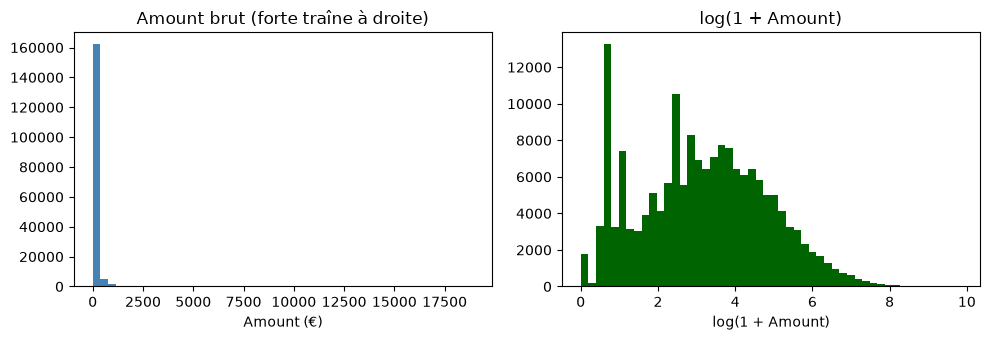

In [ ]:
# Histogramme brut de Amount et avec log(1 + Amount)
plt.figure(figsize=(10, 3.5))

plt.subplot(1, 2, 1)
plt.hist(X_train["Amount"], bins=50, color="steelblue")
plt.title("Amount brut (forte traîne à droite)")
plt.xlabel("Amount (€)")

plt.subplot(1, 2, 2)
plt.hist(np.log1p(X_train["Amount"]), bins=50, color="darkgreen")
plt.title("log(1 + Amount)")
plt.xlabel("log(1 + Amount)")

plt.tight_layout()
plt.show()

### Appliquer la mise à l'échelle (scale_amount)

In [12]:
X_train_s, X_val_s, X_test_s = utils_credit.scale_amount(X_train, X_val, X_test)

# Vérification : la médiane de Amount sur Train doit être à 0
print("Statistiques de Amount après RobustScaler (Train) :")
print(X_train_s["Amount"].describe().round(3))

Statistiques de Amount après RobustScaler (Train) :
count    170235.000
mean          0.920
std           3.386
min          -0.305
25%          -0.227
50%           0.000
75%           0.773
max         262.206
Name: Amount, dtype: float64


# 2. Comparer et prendre une décision

## a. Comparaison des modèles supervisés (Arbre de décision et Régression Logistique)


Pour chaque modèle, nous étudions 3 variantes :
1. Sans correction du déséquilibre
2. Avec pondération des classes (`class_weight='balanced'`)
3. Avec rééchantillonnage **SMOTE** (justifié par la création de données synthétiques fiables grâce à notre mise à l'échelle préalable).

Le rééchantillonnage est appliqué **exclusivement sur les données d'apprentissage** (`X_train_s`, `y_train`).